<a href="https://colab.research.google.com/github/IvanovaKaryna/123/blob/main/ML_%D0%B4%D0%B6%D1%83%D0%BD%D1%96%D0%BE%D1%80_%D0%86%D0%B2%D0%B0%D0%BD%D0%BE%D0%B2%D0%B0_3_10_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Прогноз відтоку клієнтів

**Датасет:** Telco Customer Churn, дані клієнтів телеком компанії (7043 клієнти).
**Ціль:** передбачити, чи піде клієнт (Yes), чи залишиться (No).

**План роботи:**
1. Завантаження даних
2. Аналіз даних
3. Підготовка даних
4. Моделі
5. Підбір параметрів
6. Порівняння моделей
7. Прогноз для нового клієнта
8. Висновки

## 1. Завантаження даних

In [1]:
#Імпортую потрібні бібліотеки
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

In [2]:
#Завантажую датасет за посиланням
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
print("Розмір даних:", df.shape)
df.head()

Розмір даних: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Аналіз даних

In [3]:
#Дивлюсь інформацію про стовпці та типи даних
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
#TotalCharges має тип object, бо є порожні значення, тому перетворюю його в число
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

#Перевіряю пропуски
print(df.isna().sum()[df.isna().sum() > 0])

TotalCharges    11
dtype: int64


Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73
Yes    0.27
Name: proportion, dtype: float64


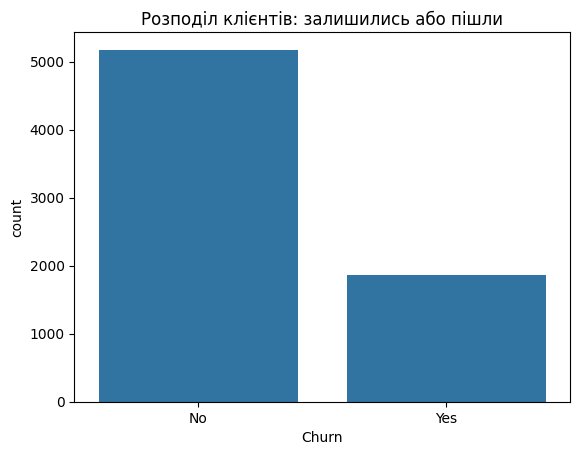

In [5]:
#Рахую скільки клієнтів пішло, а скільки залишилось
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(2))

sns.countplot(x="Churn", data=df)
plt.title("Розподіл клієнтів: залишились або пішли")
plt.show()

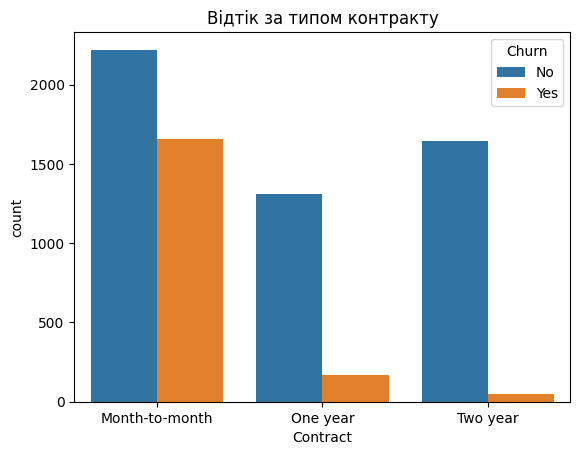

In [6]:
#Дивлюсь як відтік залежить від типу контракту
sns.countplot(x="Contract", hue="Churn", data=df)
plt.title("Відтік за типом контракту")
plt.show()

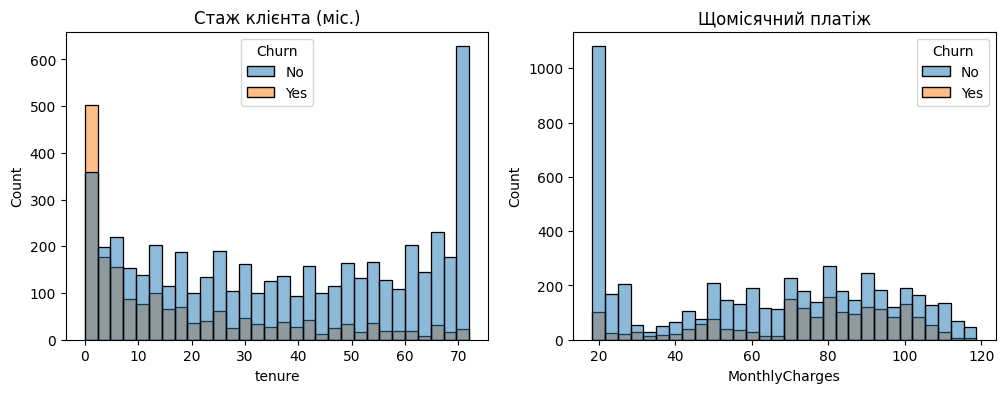

In [7]:
#Дивлюсь як відтік залежить від стажу клієнта та щомісячного платежу
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=axes[0])
axes[0].set_title("Стаж клієнта (міс.)")
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", bins=30, ax=axes[1])
axes[1].set_title("Щомісячний платіж")
plt.show()

**Висновок з аналізу:** пішли приблизно 27% клієнтів. Найчастіше йдуть клієнти з контрактом "Month-to-month", з малим стажем та з більшим щомісячним платежем.

## 3. Підготовка даних

In [8]:
#Прибираю customerID, він не потрібен для моделі
df = df.drop(columns=["customerID"])

#Заповнюю пропуски в TotalCharges медіаною
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

#Перетворюю цільову змінну в числа: Yes це 1 (піде), No це 0 (залишиться)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

In [9]:
#Перетворюю текстові ознаки в числа (one hot кодування)
df_encoded = pd.get_dummies(df, drop_first=True)

X = df_encoded.drop(columns=["Churn"])
y = df_encoded["Churn"]
print(X.shape)

(7043, 30)


In [10]:
#Ділю дані на навчальну (80%) та тестову (20%) вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

#Масштабую ознаки, це потрібно для логістичної регресії
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (5634, 30) Test: (1409, 30)


## 4. Моделі

In [11]:
#Створюю функцію для підрахунку метрик
def get_metrics(name, y_true, y_pred, y_proba):
    return {
        "Модель": name,
        "Accuracy": round(accuracy_score(y_true, y_pred), 3),
        "Precision": round(precision_score(y_true, y_pred), 3),
        "Recall": round(recall_score(y_true, y_pred), 3),
        "F1": round(f1_score(y_true, y_pred), 3),
        "ROC-AUC": round(roc_auc_score(y_true, y_proba), 3),
    }

#Сюди збираю результати всіх моделей
results = []

### Модель 1: Логістична регресія

In [12]:
#Створюю і навчаю логістичну регресію
lr = LogisticRegression(max_iter=1000, class_weight="balanced")
lr.fit(X_train_scaled, y_train)

#Роблю прогноз на тестових даних і зберігаю метрики
pred = lr.predict(X_test_scaled)
proba = lr.predict_proba(X_test_scaled)[:, 1]
results.append(get_metrics("Логістична регресія", y_test, pred, proba))
results[-1]

{'Модель': 'Логістична регресія',
 'Accuracy': 0.739,
 'Precision': 0.505,
 'Recall': 0.781,
 'F1': 0.613,
 'ROC-AUC': np.float64(0.841)}

### Модель 2: Random Forest (випадковий ліс)

In [13]:
#Створюю і навчаю випадковий ліс
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
rf.fit(X_train, y_train)

#Роблю прогноз на тестових даних і зберігаю метрики
pred = rf.predict(X_test)
proba = rf.predict_proba(X_test)[:, 1]
results.append(get_metrics("Random Forest", y_test, pred, proba))
results[-1]

{'Модель': 'Random Forest',
 'Accuracy': 0.789,
 'Precision': 0.631,
 'Recall': 0.497,
 'F1': 0.556,
 'ROC-AUC': np.float64(0.825)}

### Модель 3: Gradient Boosting (градієнтний бустинг)

In [14]:
#Створюю і навчаю градієнтний бустинг
gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)

#Роблю прогноз на тестових даних і зберігаю метрики
pred = gb.predict(X_test)
proba = gb.predict_proba(X_test)[:, 1]
results.append(get_metrics("Gradient Boosting", y_test, pred, proba))
results[-1]

{'Модель': 'Gradient Boosting',
 'Accuracy': 0.799,
 'Precision': 0.654,
 'Recall': 0.516,
 'F1': 0.577,
 'ROC-AUC': np.float64(0.843)}

## 5. Підбір параметрів

In [15]:
#Підбираю параметри для Random Forest за допомогою GridSearchCV
params = {
    "n_estimators": [100, 300],
    "max_depth": [5, 10, None],
    "min_samples_leaf": [1, 5, 10],
}

grid = GridSearchCV(RandomForestClassifier(class_weight="balanced", random_state=42),
                    params, cv=5, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

print("Найкращі параметри:", grid.best_params_)

Найкращі параметри: {'max_depth': 10, 'min_samples_leaf': 10, 'n_estimators': 300}


In [16]:
#Перевіряю Random Forest з підібраними параметрами
rf_best = grid.best_estimator_

pred = rf_best.predict(X_test)
proba = rf_best.predict_proba(X_test)[:, 1]
results.append(get_metrics("Random Forest (підібрані параметри)", y_test, pred, proba))
results[-1]

{'Модель': 'Random Forest (підібрані параметри)',
 'Accuracy': 0.758,
 'Precision': 0.53,
 'Recall': 0.778,
 'F1': 0.631,
 'ROC-AUC': np.float64(0.845)}

## 6. Порівняння моделей

In [17]:
#Роблю таблицю з результатами всіх моделей
results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False)
results_df

,Модель,Accuracy,Precision,Recall,F1,ROC-AUC
3,Random Forest (підібрані параметри),0.758,0.530,0.778,0.631,0.845
2,Gradient Boosting,0.799,0.654,0.516,0.577,0.843
0,Логістична регресія,0.739,0.505,0.781,0.613,0.841
1,Random Forest,0.789,0.631,0.497,0.556,0.825


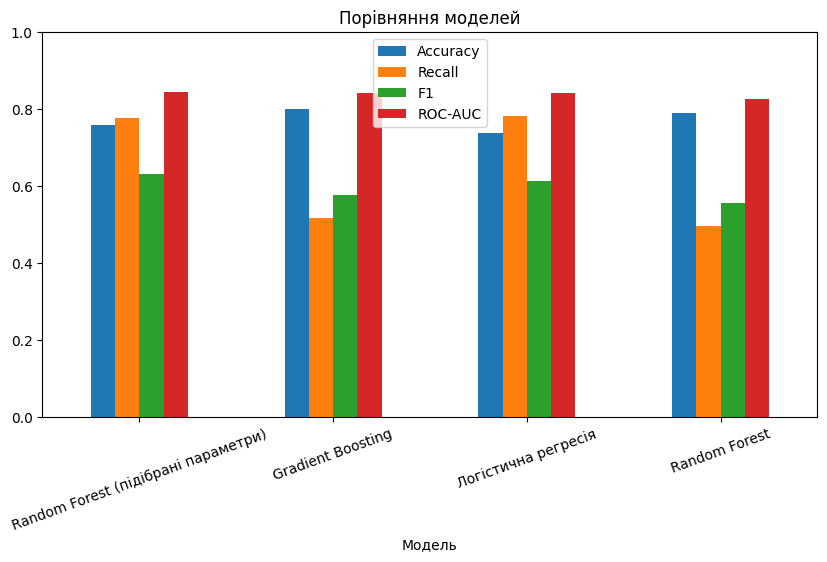

In [18]:
#Будую графік порівняння
results_df.set_index("Модель")[["Accuracy", "Recall", "F1", "ROC-AUC"]].plot(kind="bar", figsize=(10, 5))
plt.title("Порівняння моделей")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.show()

In [19]:
#Вибираю найкращу модель за ROC-AUC
best_name = results_df.iloc[0]["Модель"]
print("Найкраща модель:", best_name)

all_models = {
    "Логістична регресія": (lr, True),
    "Random Forest": (rf, False),
    "Gradient Boosting": (gb, False),
    "Random Forest (підібрані параметри)": (rf_best, False),
}
best_model, use_scaler = all_models[best_name]

Найкраща модель: Random Forest (підібрані параметри)


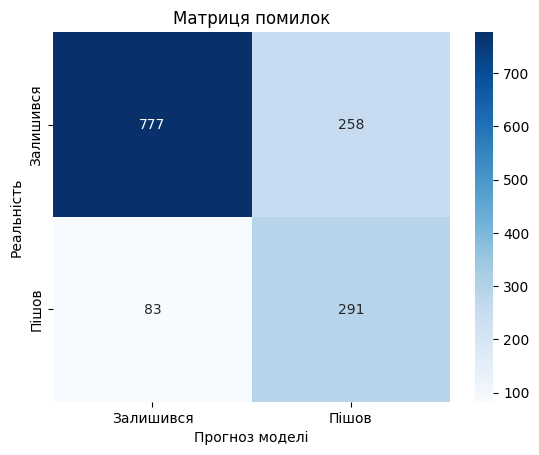

In [20]:
#Будую матрицю помилок для найкращої моделі
X_check = X_test_scaled if use_scaler else X_test
cm = confusion_matrix(y_test, best_model.predict(X_check))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Залишився", "Пішов"], yticklabels=["Залишився", "Пішов"])
plt.xlabel("Прогноз моделі")
plt.ylabel("Реальність")
plt.title("Матриця помилок")
plt.show()

## 7. Прогноз для нового клієнта

In [21]:
#Вводжу дані клієнта (значення можна змінювати)
new_client = {
    "gender": "Female", "SeniorCitizen": 0, "Partner": "No", "Dependents": "No",
    "tenure": 2, "PhoneService": "Yes", "MultipleLines": "No",
    "InternetService": "Fiber optic", "OnlineSecurity": "No", "OnlineBackup": "No",
    "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "No",
    "StreamingMovies": "No", "Contract": "Month-to-month", "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check", "MonthlyCharges": 80.5, "TotalCharges": 161.0,
}

#Пишу функцію, яка робить прогноз для одного клієнта
def predict_client(client):
    row = pd.DataFrame([client])
    row = pd.get_dummies(row)
    #Роблю такі самі стовпці, як при навчанні моделі
    row = row.reindex(columns=X.columns, fill_value=0)
    if use_scaler:
        row = scaler.transform(row)
    proba = best_model.predict_proba(row)[0, 1]
    if proba >= 0.5:
        print(f"Клієнт ПІДЕ. Ймовірність відтоку: {proba:.0%}")
    else:
        print(f"Клієнт ЗАЛИШИТЬСЯ. Ймовірність відтоку: {proba:.0%}")

predict_client(new_client)

Клієнт ПІДЕ. Ймовірність відтоку: 85%


In [22]:
#Перевіряю другий приклад: лояльний клієнт з довгим контрактом
loyal_client = new_client.copy()
loyal_client["tenure"] = 60
loyal_client["Contract"] = "Two year"
loyal_client["InternetService"] = "DSL"
loyal_client["PaymentMethod"] = "Bank transfer (automatic)"
loyal_client["MonthlyCharges"] = 45.0
loyal_client["TotalCharges"] = 2700.0

predict_client(loyal_client)

Клієнт ЗАЛИШИТЬСЯ. Ймовірність відтоку: 12%


## 8. Висновки

1. Я побудувала та порівняла три моделі (логістична регресія, Random Forest, Gradient Boosting), а також підібрала параметри для Random Forest за допомогою GridSearchCV.
2. Усі моделі показали схожі результати (ROC-AUC близько 0.84), а найкращою за ROC-AUC виявилась модель, яка стоїть першою в таблиці порівняння.
3. Пішло лише близько 27% клієнтів, тому Accuracy не дуже показова, і я додатково дивилась на Recall та F1.
4. Найбільше на відтік впливають малий стаж клієнта, контракт "Month-to-month" та більший щомісячний платіж, а клієнти з довгим контрактом майже не йдуть.
5. Модель можна використовувати, щоб знаходити клієнтів із високим ризиком відтоку і пропонувати їм знижки або довший контракт.